In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data Analysis and visualization of last 30 days data

In [2]:
df30 = pd.read_csv('cleaned_bagdolLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6230465,Bagdol,relativehumidity,61.0,%,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,06:45:00
1,6230465,Bagdol,relativehumidity,60.0,%,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,07:45:00
2,6230465,Bagdol,relativehumidity,51.0,%,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,08:45:00
3,6230465,Bagdol,relativehumidity,45.0,%,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,09:45:00
4,6230465,Bagdol,relativehumidity,45.0,%,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
714,6230465,Bagdol,relativehumidity,54.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,01:45:00
715,6230465,Bagdol,relativehumidity,54.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,02:45:00
716,6230465,Bagdol,relativehumidity,55.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,03:45:00
717,6230465,Bagdol,relativehumidity,56.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,04:45:00


In [3]:
df30['date'].unique()

<ArrowStringArray>
['2026-09-12', '2026-09-13', '2026-09-14', '2026-09-15', '2026-09-16',
 '2026-09-17', '2026-09-18', '2026-09-19', '2026-09-20', '2026-09-21',
 '2026-09-22', '2026-09-23', '2026-09-24', '2026-09-25', '2026-09-26',
 '2026-09-27', '2026-09-28', '2026-09-29', '2026-09-30', '2026-10-01',
 '2026-10-02', '2026-10-03', '2026-10-04', '2026-10-05', '2026-10-06',
 '2026-10-07', '2026-10-08', '2026-10-09', '2026-10-10', '2026-10-11',
 '2026-10-12']
Length: 31, dtype: str

#### Aggrigating hourly data to daily means, and filling only short gaps(1 to 2 days) by interpolation

In [16]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

# Save the aggregated result
# daily_means.to_csv("Gothatar_daily_relative_humidity_means.csv", index=False)

In [17]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-12,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,50.17,18
1,2026-09-13,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,52.33,24
2,2026-09-14,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,52.00,24
3,2026-09-15,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,52.50,24
4,2026-09-16,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,51.75,24
5,2026-09-17,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,51.33,24
6,2026-09-18,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,52.71,24
7,2026-09-19,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,52.61,23
8,2026-09-20,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,50.79,24
9,2026-09-21,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,52.50,24


/tmp/ipykernel_26350/2188626376.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


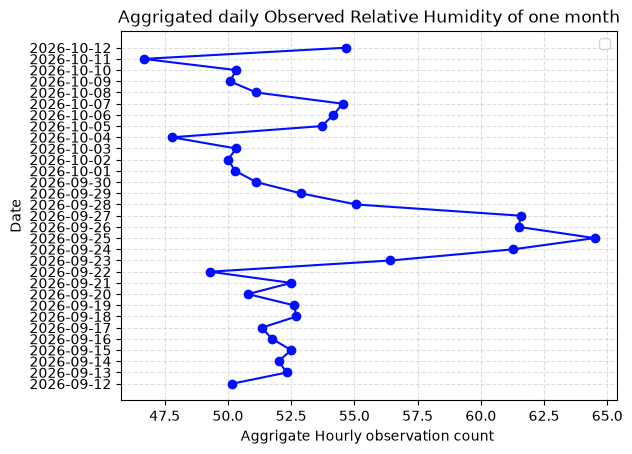

In [19]:
# Line plot
plt.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Relative Humidity of one month")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data analysis and Visualization of last 7 days

In [20]:
df7 = pd.read_csv('cleaned_bagdolLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6230465,Bagdol,relativehumidity,57.0,%,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,06:45:00
1,6230465,Bagdol,relativehumidity,55.0,%,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,07:45:00
2,6230465,Bagdol,relativehumidity,45.0,%,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,08:45:00
3,6230465,Bagdol,relativehumidity,45.0,%,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,09:45:00
4,6230465,Bagdol,relativehumidity,45.0,%,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6230465,Bagdol,relativehumidity,54.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,01:45:00
164,6230465,Bagdol,relativehumidity,54.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,02:45:00
165,6230465,Bagdol,relativehumidity,55.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,03:45:00
166,6230465,Bagdol,relativehumidity,56.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,04:45:00


In [21]:
df7['date'].unique()

<ArrowStringArray>
['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09',
 '2026-10-10', '2026-10-11', '2026-10-12']
Length: 8, dtype: str

#### Aggrigating hourly data to daily means, and filling only short gaps(1 to 2 days) by interpolation

In [22]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df7.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

# Save the aggregated result
# daily_means.to_csv("Gothatar_daily_relative_humidity_means.csv", index=False)

In [23]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-10-05,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,53.33,18
1,2026-10-06,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,54.17,24
2,2026-10-07,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,54.54,24
3,2026-10-08,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,51.12,24
4,2026-10-09,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,50.08,24
5,2026-10-10,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,50.33,24
6,2026-10-11,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,46.67,24
7,2026-10-12,6230465,Bagdol,relativehumidity,%,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,54.67,6


/tmp/ipykernel_26350/1577824620.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


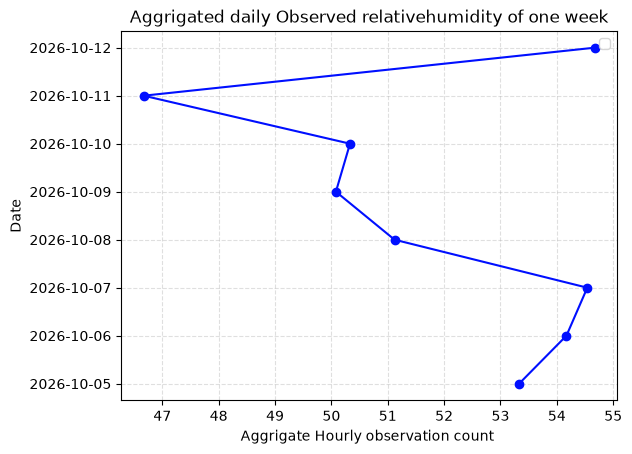

In [24]:
# Line plot
plt.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 24 hours

In [26]:
df24 = pd.read_csv('cleaned_bagdolLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6230465,Bagdol,relativehumidity,58.0,%,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,06:45:00
1,6230465,Bagdol,relativehumidity,57.0,%,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,07:45:00
2,6230465,Bagdol,relativehumidity,41.0,%,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,08:45:00
3,6230465,Bagdol,relativehumidity,38.0,%,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,09:45:00
4,6230465,Bagdol,relativehumidity,40.0,%,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,10:45:00
5,6230465,Bagdol,relativehumidity,37.0,%,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,11:45:00
6,6230465,Bagdol,relativehumidity,37.0,%,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,12:45:00
7,6230465,Bagdol,relativehumidity,35.0,%,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,13:45:00
8,6230465,Bagdol,relativehumidity,35.0,%,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,14:45:00
9,6230465,Bagdol,relativehumidity,36.0,%,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,15:45:00


In [27]:
df24['time'].unique()

<ArrowStringArray>
['06:45:00', '07:45:00', '08:45:00', '09:45:00', '10:45:00', '11:45:00',
 '12:45:00', '13:45:00', '14:45:00', '15:45:00', '16:45:00', '17:45:00',
 '18:45:00', '19:45:00', '20:45:00', '21:45:00', '22:45:00', '23:45:00',
 '00:45:00', '01:45:00', '02:45:00', '03:45:00', '04:45:00', '05:45:00']
Length: 24, dtype: str

In [28]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_26350/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


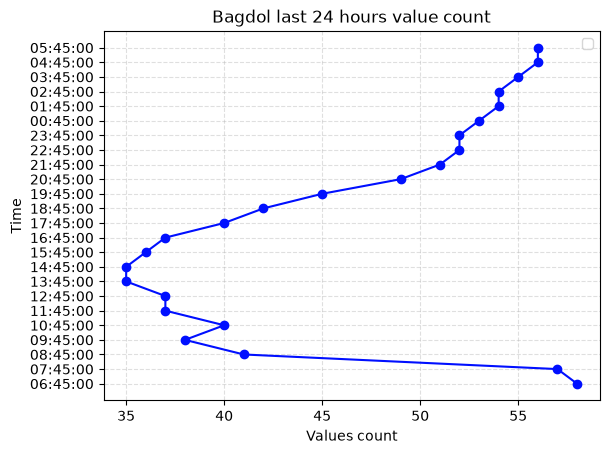

In [29]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()